# Calorie expenditure prediction with XGBoost
## Group 2 · OmahTI Learning Center · Data Science & AI

A reproducible CRISP-DM study using the original course-supplied CSV files. This revision separates model selection from internal holdout evaluation, fits preprocessing within validation folds, and records the complete run. The original submission is preserved in `notebooks/archive/original-submission.ipynb`.

The data represents **exercise calorie expenditure**, not food intake. It is an academic prediction task, not a clinically validated energy-expenditure calculator.

## 1. Business understanding

Can exercise and participant attributes predict the supplied `Calories` outcome better than a constant or linear baseline? The original course's “TiProduction” business scenario is a teaching scenario, not evidence of a commercial client or deployed product.

The deliverables are a documented comparison, error diagnostics, a reusable preprocessing/model pipeline, and predictions for the unlabeled submission file. RMSE is the primary selection metric; MAE and R² provide complementary views.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import Image, display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'calorie_prediction.py').exists() and (p / 'Train.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned repository containing Train.csv and calorie_prediction.py.')
sys.path.insert(0, str(ROOT))
from calorie_prediction import FEATURES, profile_groups, split_development_holdout, validate_frame, run_experiment
train = validate_frame(pd.read_csv(ROOT / 'Train.csv', float_precision='round_trip'), labeled=True)
submission_inputs = validate_frame(pd.read_csv(ROOT / 'Test.csv', float_precision='round_trip'), labeled=False)
print(f'Labeled rows: {len(train):,}; unlabeled submission rows: {len(submission_inputs):,}')

Labeled rows: 9,000; unlabeled submission rows: 6,000


## 2. Data understanding and audit

`Train.csv` supplies 9,000 labeled rows; `Test.csv` supplies 6,000 rows without `Calories`. `User_ID` is retained for traceability and submission order, and excluded from predictors. Predictor units and original measurement methods are not fully documented in the course material; energy errors are reported in the dataset's `Calories` units.

No claim of verified real-world participants, synthetic generation, medical ground truth, or a separate dataset license is made. Categorical values describe the supplied field, not a comprehensive representation of gender.

In [2]:
audit = pd.DataFrame({
    'rows': [len(train), len(submission_inputs)],
    'missing_cells': [int(train.isna().sum().sum()), int(submission_inputs.isna().sum().sum())],
    'duplicate_ids': [int(train.User_ID.duplicated().sum()), int(submission_inputs.User_ID.duplicated().sum())],
    'repeated_predictor_profiles': [int(pd.Series(profile_groups(train)).duplicated().sum()), int(pd.Series(profile_groups(submission_inputs)).duplicated().sum())],
}, index=['Train.csv', 'Test.csv'])
display(audit)
assert set(train.User_ID).isdisjoint(submission_inputs.User_ID)
assert 'Calories' not in submission_inputs
display(train.dtypes.rename('dtype').to_frame())

,rows,missing_cells,duplicate_ids,repeated_predictor_profiles
Train.csv,9000,0,0,1
Test.csv,6000,0,0,0


,dtype
User_ID,int64
Gender,object
Age,int64
Height,float64
Weight,float64
Duration,float64
Heart_Rate,float64
Body_Temp,float64
Calories,float64


## 3. Reserve the holdout before exploratory modeling

One predictor profile appears twice under distinct IDs. A seeded grouped 80/20 split and shuffled GroupKFold keep identical profiles together. The group key uses predictors only, never target labels. This protects against exact-profile duplication across development/holdout and across CV folds; it cannot detect undocumented participant, site, or temporal dependencies.

Exploration below uses development rows only. Earlier project versions already inspected the wider dataset, so this revised split remains **internal re-evaluation**, not independent external validation.

In [3]:
development, holdout = split_development_holdout(train, seed=42)
X_dev = train.iloc[development][FEATURES]
y_dev = train.iloc[development]['Calories']
assert set(profile_groups(train.iloc[development])).isdisjoint(profile_groups(train.iloc[holdout]))
print(f'Development: {len(development):,}; holdout: {len(holdout):,}')
display(X_dev.describe(include='all'))
display(X_dev.select_dtypes(include='number').assign(Calories=y_dev).corr()['Calories'].sort_values(ascending=False).to_frame('development Pearson correlation'))

Development: 7,200; holdout: 1,800


,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
count,7200,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000
unique,2,NaN,NaN,NaN,NaN,NaN,NaN
top,female,NaN,NaN,NaN,NaN,NaN,NaN
freq,3625,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,42.728611,174.555417,75.044167,15.406250,95.355278,40.011694
std,NaN,16.949275,14.179381,15.004347,8.361989,9.604408,0.788120
min,NaN,20.000000,123.000000,36.000000,1.000000,69.000000,37.100000
25%,NaN,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000
50%,NaN,39.000000,175.000000,74.000000,15.000000,95.000000,40.200000
75%,NaN,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000


,development Pearson correlation
Calories,1.000000
Duration,0.955568
Heart_Rate,0.899444
Body_Temp,0.825809
Age,0.153386
Weight,0.045047
Height,0.025273


### Interpreting the exploration

Duration, heart rate, and body temperature co-vary with the supplied expenditure outcome. These are observed associations, not estimates of causal effects. No measured fitness level or exercise-type variable is available. The notebook does not infer those attributes from correlations.

Unusual records are retained unless they violate a basic schema/finite-value/positivity check. Unlike the original notebook, no full-dataset IQR thresholds are learned and no test-specific clipping rule changes the meaning of an input.

## 4. Preparation inside each training fold

The scikit-learn Pipeline includes a ColumnTransformer: numerical median imputation, categorical imputation, and one-hot encoding with unseen-category handling. Linear regression additionally scales numerical inputs; tree models do not need scaling. The supplied files currently have no missing values, but these rules make inference behavior explicit.

Every fold fits its own preprocessing. Targets and IDs never enter the transformer. Input CSVs are not changed. Training/test schemas are validated and feature ordering is explicit.

## 5. Modeling and bounded hyperparameter search

Compare a mean DummyRegressor, linear regression, random forest, and XGBoost using the same five development folds. A seeded randomized search evaluates **12 XGBoost candidates** on those folds. RMSE, MAE, and R² are computed in one CV pass. Histogram-based XGBoost and a single parallelism layer bound the computational work.

Selection uses development mean RMSE only. Search CV results are selection statistics and can be optimistic after searching; no nested-CV performance claim is made. The frozen chosen pipeline is then evaluated once on the internal holdout. No parameters are changed in response to that score.

In [4]:
summary = run_experiment(ROOT, ROOT / 'results', iterations=12, folds=5, jobs=4, seed=42)
print('Selected:', summary['selected_model'])
comparison = pd.read_csv(ROOT / 'results/cv_scores.csv')
display(comparison.round(4))

Cross-validating Mean baseline...


Cross-validating Linear regression...


Cross-validating Random forest...


Cross-validating XGBoost baseline...


Searching 12 XGBoost candidates across 5 development folds...


Selected XGBoost tuned; holdout RMSE=1.2056


Selected: XGBoost tuned


,model,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
0,XGBoost tuned,1.3715,0.0817,0.9682,0.0286,0.9995,0.0001
1,XGBoost baseline,2.7232,0.1110,1.8448,0.0429,0.9981,0.0002
2,Random forest,3.6348,0.2239,2.2311,0.0753,0.9966,0.0004
3,Linear regression,11.2185,0.3652,8.2838,0.2614,0.9678,0.0016
4,Mean baseline,62.5854,0.5768,53.3813,0.4031,-0.0009,0.0008


## 6. Holdout evaluation and error analysis

RMSE penalizes large errors; MAE describes typical absolute error; R² compares squared error to the holdout mean reference. None establishes accuracy outside this dataset. Predictions are not clipped after seeing results. The tables and figures below are generated by this execution, not manually copied from a leaderboard.

,internal holdout
rmse,1.205553
mae,0.877554
r2,0.999611
mean_error,0.011446


Negative holdout predictions: 0


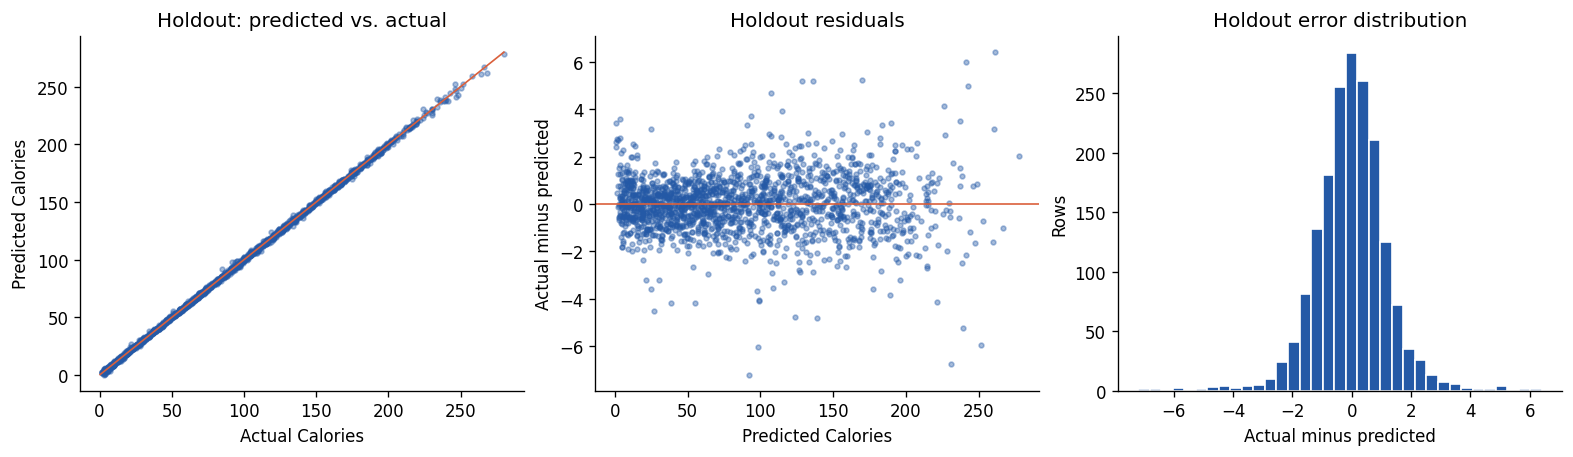

,variable,group,n,rmse,mae,r2,mean_error
0,Gender,female,912,1.0856,0.7826,0.9996,-0.0331
1,Gender,male,888,1.3175,0.9751,0.9996,0.0572
2,Age band,40-59,523,1.2238,0.8848,0.9996,0.0616
3,Age band,under 40,922,1.0812,0.8143,0.9996,0.0071
4,Age band,60+,355,1.4582,1.0313,0.9995,-0.0511


In [5]:
display(pd.Series(summary['holdout_metrics'], name='internal holdout').to_frame().round(6))
print('Negative holdout predictions:', summary['negative_holdout_predictions'])
display(Image(filename=str(ROOT / 'assets/holdout_diagnostics.png')))
display(pd.read_csv(ROOT / 'results/subgroup_metrics.csv').round(4))

### Model reliance and limitations

Permutation importance measures how much this fitted model's holdout RMSE increases when one raw input is shuffled. Correlated predictors can share or mask importance; a large score is not causal evidence. Subgroup tables report observed errors with sample counts, not a fairness guarantee.

The data's collection process, measurement precision, and provenance are incompletely documented. The split is random and does not represent future time, unseen hospitals, or a new population. Generalization, calibration/uncertainty, physical constraints, and real-use utility require separate investigation. Very high R² may reflect a regular relationship in the supplied data rather than real-world predictive validity.

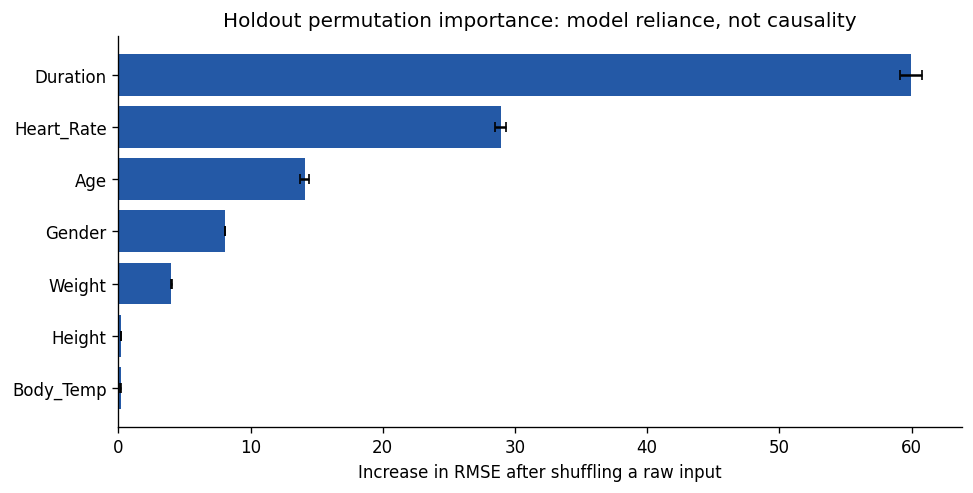

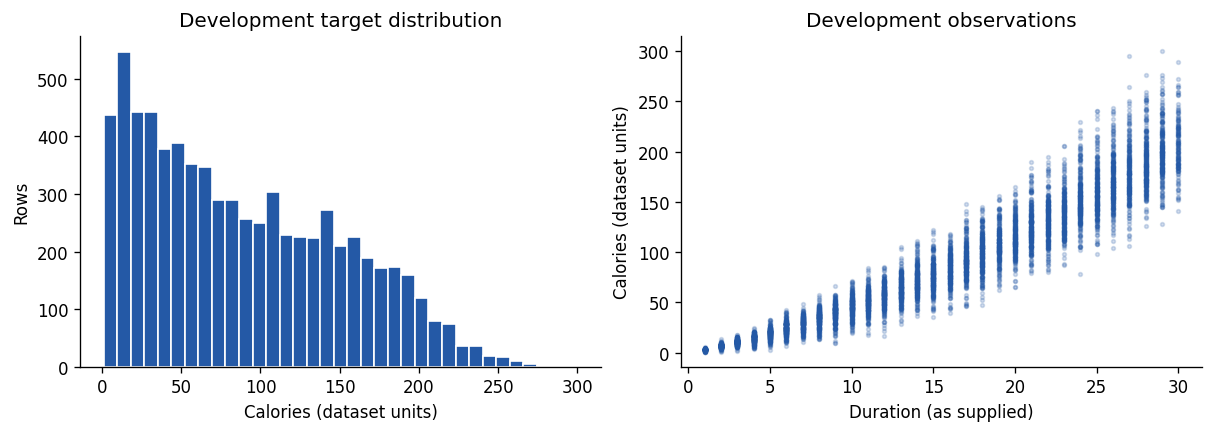

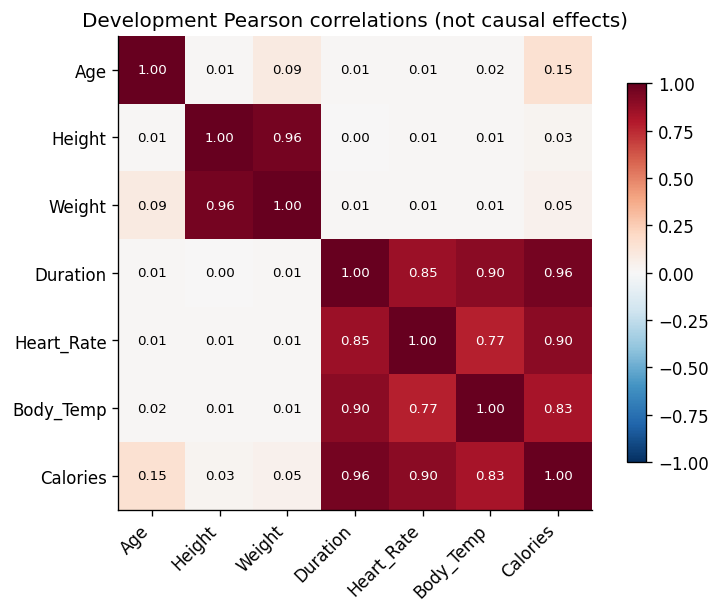

In [6]:
display(Image(filename=str(ROOT / 'assets/permutation_importance.png')))
display(Image(filename=str(ROOT / 'assets/development_eda.png')))
display(Image(filename=str(ROOT / 'assets/development_correlations.png')))

## 7. Submission and reproducibility

Only after holdout evaluation, a separate clone is fitted on all 9,000 labeled rows for the 6,000-row submission. That refitted model is **not** the model whose holdout metrics are reported. `Test.csv` contains no labels, so no submission-file RMSE can be computed here.

`artifacts/development_model.joblib`, `artifacts/submission_model.joblib`, and `artifacts/submission.csv` are generated locally and ignored by Git. The checked-in summary records source SHA-256 hashes, library versions, split sizes, seed, search settings, and selected parameters. `split_membership.csv` and fold metrics make the evaluation auditable. XGBoost's NaN missing-value parameter is represented by the string `"NaN"` in standards-compliant JSON.

In [7]:
submission = pd.read_csv(ROOT / 'artifacts/submission.csv')
assert submission.columns.tolist() == ['User_ID', 'Calories']
assert submission.User_ID.tolist() == submission_inputs.User_ID.tolist()
assert len(submission) == 6000
display(submission.head())
display(pd.Series(summary['data']['source_sha256'], name='SHA-256'))
display(pd.Series(summary['versions'], name='saved-run environment'))

,User_ID,Calories
0,12549363,172.977829
1,13995058,191.221497
2,17223277,53.028336
3,18175714,160.730881
4,17841615,225.292389


Train.csv    0faa47b56ffec334bebeb7f009cee1839858e4a4e1377c...
Test.csv     d0108887f6967a0cbfa443825437169a7ba2ea1d01f729...
Name: SHA-256, dtype: object

python          3.13.3
numpy            2.2.6
pandas           2.2.3
scikit-learn     1.7.2
xgboost          3.0.5
matplotlib      3.10.7
joblib           1.5.2
Name: saved-run environment, dtype: object

## References and next steps

- [scikit-learn: avoiding data leakage with pipelines](https://scikit-learn.org/stable/common_pitfalls.html)
- [Grouped cross-validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html)
- [XGBoost scikit-learn API](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBRegressor)

Next steps require new evidence: document dataset provenance and units, validate on independent data with a defensible grouping/time scheme, study prediction intervals, and investigate error patterns without repurposing this holdout for further tuning.